# PARTE I - Análise Principal

# Análise dos horários de pico e vale do SIN em 2025

## 1. Objetivo

Este notebook tem como objetivo responder à seguinte pergunta:

> **Como varia a composição da geração para atendimento à carga entre os horários de pico e de vale no Sistema Interligado Nacional ao longo de 2025?**

A análise considera como:

- **pico:** o instante de maior carga de cada dia;
- **vale:** o instante de menor carga de cada dia.

Para cada dia $d$:

$$
C_{\text{pico},d} = \max_h(C_{d,h})
$$

$$
C_{\text{vale},d} = \min_h(C_{d,h})
$$

A partir desses instantes serão comparadas as gerações hidráulica, térmica, eólica e solar.

A análise principal utiliza a **carga bruta**. A carga líquida será explorada posteriormente como análise complementar.

## 2. Carregamento e seleção dos dados

A análise utiliza a base processada anteriormente no notebook `01_preparacao_dados.ipynb`.

Como a pergunta principal está relacionada ao comportamento agregado do Sistema Interligado Nacional, nesta etapa serão selecionados somente os registros identificados como `SIN`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

In [2]:
# Paleta de cores padronizada para os gráficos do projeto
CORES_FONTES = {
    "Hidráulica": "#2F75B5",   # azul
    "Térmica": "#E67E22",      # laranja
    "Eólica": "#70AD47",       # verde
    "Solar": "#F4C430"         # amarelo/dourado
}

# Cores utilizadas para outras variáveis da análise
COR_CARGA = "#262626"          # preto/cinza escuro
COR_CARGA_LIQUIDA = "#A6A6A6"  # cinza claro

COR_PICO = "#E15759"           # vermelho/coral
COR_VALE = "#4E79A7"           # azul

In [5]:
# Define os caminhos utilizados no projeto
PASTA_PROJETO = Path.cwd().parent
PASTA_DADOS_PROCESSADOS = PASTA_PROJETO / "dados" / "processados"
PASTA_SAIDAS = PASTA_PROJETO / "saidas"

ARQUIVO_PROCESSADO = PASTA_DADOS_PROCESSADOS / "balanco_energia_2025_processado.csv"

# Realiza a leitura da base processada
df = pd.read_csv(
    ARQUIVO_PROCESSADO,
    sep=";",
    parse_dates=["din_instante", "data"]
)

print(f"Base completa: {df.shape[0]:,} registros")

Base completa: 43,800 registros


In [6]:
# Seleciona somente os registros do Sistema Interligado Nacional
df_sin = (
    df[df["id_subsistema"] == "SIN"]
    .copy()
    .sort_values("din_instante")
    .reset_index(drop=True)
)

print(f"Registros do SIN: {len(df_sin):,}")
print(
    f"Período: {df_sin['din_instante'].min()} "
    f"a {df_sin['din_instante'].max()}"
)

df_sin.head()

Registros do SIN: 8,760
Período: 2025-01-01 00:00:00 a 2025-12-31 23:00:00


,id_subsistema,nom_subsistema,din_instante,data,ano,mes,hora,dia_semana_num,dia_semana,fim_semana,...,val_gereolica,val_gersolar,val_carga,val_intercambio,geracao_total,carga_liquida,part_hidraulica,part_termica,part_eolica,part_solar
0,SIN,SISTEMA INTERLIGADO NACIONAL,2025-01-01 00:00:00,2025-01-01,2025,1,0,2,Quarta-feira,False,...,17662.519,1.000,65277.57,0.0,65277.569,47614.051,62.469716,10.471190,27.057562,0.001532
1,SIN,SISTEMA INTERLIGADO NACIONAL,2025-01-01 01:00:00,2025-01-01,2025,1,1,2,Quarta-feira,False,...,17823.560,1.000,65714.82,0.0,65714.822,47890.260,62.535447,10.340443,27.122587,0.001522
2,SIN,SISTEMA INTERLIGADO NACIONAL,2025-01-01 02:00:00,2025-01-01,2025,1,2,2,Quarta-feira,False,...,18394.964,1.000,65579.63,0.0,65579.630,47183.666,61.762794,10.185867,28.049814,0.001525
3,SIN,SISTEMA INTERLIGADO NACIONAL,2025-01-01 03:00:00,2025-01-01,2025,1,3,2,Quarta-feira,False,...,18176.561,1.000,64590.49,0.0,64590.486,46412.929,61.673284,10.183932,28.141236,0.001548
4,SIN,SISTEMA INTERLIGADO NACIONAL,2025-01-01 04:00:00,2025-01-01,2025,1,4,2,Quarta-feira,False,...,18550.189,13.463,63615.00,0.0,63615.001,45051.348,60.449967,10.368784,29.160086,0.021163


## 3. Perfil horário da carga

Inicialmente será analisado o comportamento médio da carga do SIN ao longo das 24 horas do dia.

Para cada hora $h$, será calculada a carga média observada ao longo de 2025:

$$
\overline{C}_h
=
\frac{1}{n_h}
\sum C_{d,h}
$$

Essa análise permite identificar o perfil diário típico da carga antes da determinação dos picos e vales de cada dia.


In [7]:
# Calcula a carga média para cada hora do dia
perfil_horario = (
    df_sin
    .groupby("hora", as_index=False)
    .agg(
        carga_media=("val_carga", "mean")
    )
)

perfil_horario

,hora,carga_media
0,0,75668.304438
1,1,72375.722822
2,2,70167.184356
3,3,68895.824521
4,4,68657.655315
5,5,69641.623973
6,6,71905.869425
7,7,75155.798384
8,8,78221.488082
9,9,79627.282904


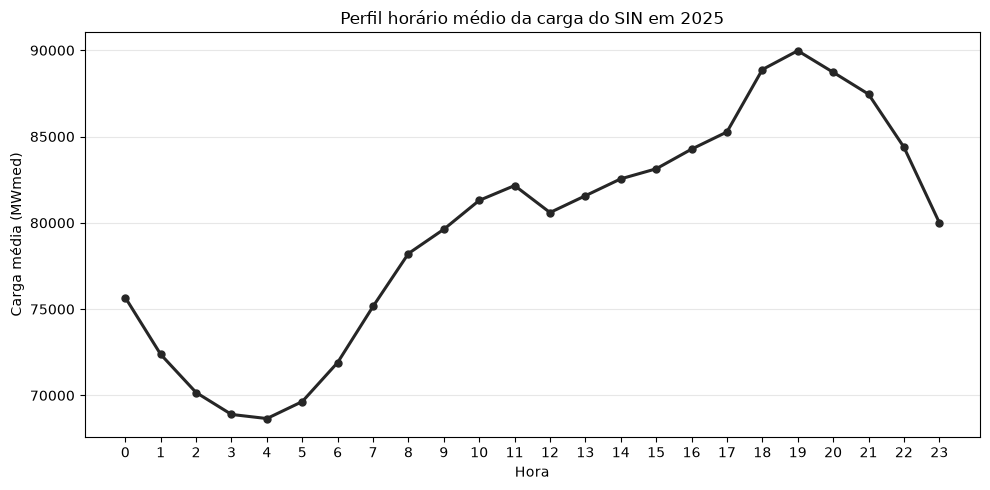

In [8]:
# Cria o gráfico do perfil horário médio da carga
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    perfil_horario["hora"],
    perfil_horario["carga_media"],
    marker="o",
    color=COR_CARGA,
    linewidth=2.2,
    markersize=5
)

ax.set_title("Perfil horário médio da carga do SIN em 2025")
ax.set_xlabel("Hora")
ax.set_ylabel("Carga média (MWmed)")
ax.set_xticks(range(24))
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    PASTA_SAIDAS / "01_perfil_horario_carga.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

## 4. Identificação dos picos e vales diários

Para cada dia de 2025 serão identificados:

- o instante de **maior carga**, classificado como pico;
- o instante de **menor carga**, classificado como vale.

Dessa forma, cada dia contribuirá com duas observações para a análise.

Como 2025 possui 365 dias, são esperadas:

$$
365\ \text{observações de pico}
$$

e

$$
365\ \text{observações de vale}
$$

In [9]:
# Identifica o índice do maior valor de carga de cada dia
indices_pico = (
    df_sin
    .groupby("data")["val_carga"]
    .idxmax()
)

# Identifica o índice do menor valor de carga de cada dia
indices_vale = (
    df_sin
    .groupby("data")["val_carga"]
    .idxmin()
)

In [10]:
# Recupera os registros referentes aos picos
df_picos = df_sin.loc[indices_pico].copy()
df_picos["condicao"] = "Pico"

# Recupera os registros referentes aos vales
df_vales = df_sin.loc[indices_vale].copy()
df_vales["condicao"] = "Vale"

print(f"Picos identificados: {len(df_picos)}")
print(f"Vales identificados: {len(df_vales)}")

Picos identificados: 365
Vales identificados: 365


In [11]:
# Consolida picos e vales em uma única base de análise
df_pico_vale = pd.concat(
    [df_picos, df_vales],
    ignore_index=True
)

df_pico_vale = (
    df_pico_vale
    .sort_values(["data", "condicao"])
    .reset_index(drop=True)
)

df_pico_vale[
    [
        "data",
        "condicao",
        "hora",
        "val_carga",
        "val_gerhidraulica",
        "val_gertermica",
        "val_gereolica",
        "val_gersolar"
    ]
].head(10)

,data,condicao,hora,val_carga,val_gerhidraulica,val_gertermica,val_gereolica,val_gersolar
0,2025-01-01,Pico,20,77888.60,56157.835,6565.360,15164.400,1.001
1,2025-01-01,Vale,8,59826.43,28334.113,6508.609,7775.316,17208.390
2,2025-01-02,Pico,20,88179.35,63517.642,6467.518,18193.192,1.000
3,2025-01-02,Vale,5,64243.37,40150.354,6548.769,16790.928,753.319
4,2025-01-03,Pico,20,88886.72,65666.543,6433.465,16785.712,1.000
5,2025-01-03,Vale,5,69646.39,44541.367,6447.772,17858.819,798.434
6,2025-01-04,Pico,20,86502.57,64966.851,6272.384,15262.332,1.000
7,2025-01-04,Vale,6,69406.37,45742.474,6308.327,11224.579,6130.987
8,2025-01-05,Pico,20,83688.46,63971.537,6556.679,13159.241,1.000
9,2025-01-05,Vale,7,64249.41,34719.844,6461.204,9493.533,13574.832


### 4.1 Extremos anuais de carga

Como complemento à análise dos picos e vales diários, são identificados os maiores e menores valores observados ao longo de 2025.

A análise considera:

- o **maior pico diário do ano**;
- o **menor vale diário do ano**.

Esses valores ajudam a contextualizar a magnitude dos extremos observados em relação ao comportamento médio apresentado anteriormente.

In [39]:
# Identifica o maior pico de carga observado em 2025
maior_pico = df_picos.loc[
    df_picos["val_carga"].idxmax()
]

# Identifica o menor vale de carga observado em 2025
menor_vale = df_vales.loc[
    df_vales["val_carga"].idxmin()
]

# Consolida os resultados em uma tabela
extremos_anuais = pd.DataFrame({
    "Indicador": [
        "Maior pico do ano",
        "Menor vale do ano"
    ],
    "Data": [
        maior_pico["data"],
        menor_vale["data"]
    ],
    "Hora": [
        maior_pico["hora"],
        menor_vale["hora"]
    ],
    "Carga (MWmed)": [
        maior_pico["val_carga"],
        menor_vale["val_carga"]
    ]
})

# Formata a hora para facilitar a leitura
extremos_anuais["Horário"] = (
    extremos_anuais["Hora"]
    .astype(int)
    .astype(str)
    .str.zfill(2)
    + ":00"
)

# Mantém apenas as colunas de interesse
extremos_anuais = extremos_anuais[
    ["Indicador", "Data", "Horário", "Carga (MWmed)"]
]

extremos_anuais

,Indicador,Data,Horário,Carga (MWmed)
0,Maior pico do ano,2025-02-26,14:00,106148.66
1,Menor vale do ano,2025-08-10,14:00,55129.83


## 5. Distribuição dos horários de pico e vale

Após a identificação dos extremos diários de carga, será analisada a frequência com que os picos e vales ocorreram em cada hora do dia.

Essa análise permite verificar se existe concentração dos extremos em determinados períodos.

In [12]:
# Conta quantos picos e vales ocorreram em cada hora
frequencia_horarios = (
    df_pico_vale
    .groupby(["condicao", "hora"])
    .size()
    .reset_index(name="quantidade_dias")
)

frequencia_horarios

,condicao,hora,quantidade_dias
0,Pico,11,1
1,Pico,14,32
2,Pico,15,20
3,Pico,16,5
4,Pico,18,137
5,Pico,19,135
6,Pico,20,20
7,Pico,21,15
8,Vale,3,148
9,Vale,4,118


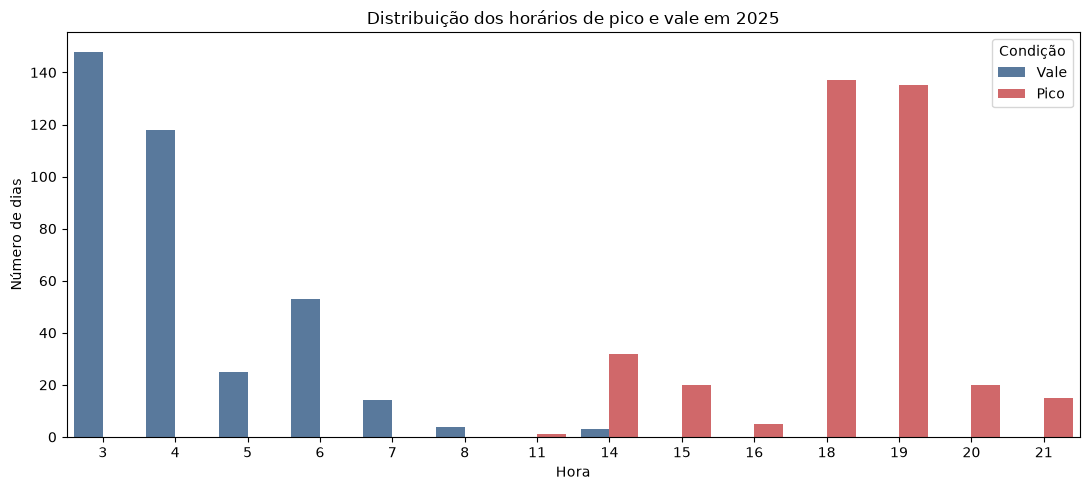

In [13]:
# Compara a distribuição dos horários de pico e vale
fig, ax = plt.subplots(figsize=(11, 5))

sns.barplot(
    data=frequencia_horarios,
    x="hora",
    y="quantidade_dias",
    hue="condicao",
    hue_order=["Vale", "Pico"],
    palette={
        "Vale": COR_VALE,
        "Pico": COR_PICO
    },
    ax=ax
)


ax.set_title("Distribuição dos horários de pico e vale em 2025")
ax.set_xlabel("Hora")
ax.set_ylabel("Número de dias")
ax.legend(title="Condição")

plt.tight_layout()

plt.savefig(
    PASTA_SAIDAS / "02_horarios_pico_vale.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

## 6. Composição da geração nos horários de pico e vale

Nesta etapa será comparada a geração média de cada fonte nos instantes classificados como pico e vale.

A comparação será realizada para:

- geração hidráulica;
- geração térmica;
- geração eólica;
- geração solar.

Além dos valores absolutos em MWmed, será analisada a participação percentual de cada fonte na geração total.

In [15]:
# Calcula a geração média de cada fonte nos horários de pico e vale
composicao_media = (
    df_pico_vale
    .groupby("condicao")
    .agg(
        hidraulica=("val_gerhidraulica", "mean"),
        termica=("val_gertermica", "mean"),
        eolica=("val_gereolica", "mean"),
        solar=("val_gersolar", "mean"),
        carga=("val_carga", "mean")
    )
)

composicao_media

,hidraulica,termica,eolica,solar,carga
condicao,,,,,
Pico,62595.735819,10460.678710,14423.201997,3778.883164,90877.103836
Vale,40694.216795,10172.636841,15703.664364,1785.791655,68085.209753


In [16]:
# Calcula a participação média de cada fonte nos horários de pico e vale
participacao_media = (
    df_pico_vale
    .groupby("condicao")
    .agg(
        hidraulica=("part_hidraulica", "mean"),
        termica=("part_termica", "mean"),
        eolica=("part_eolica", "mean"),
        solar=("part_solar", "mean")
    )
)

participacao_media

,hidraulica,termica,eolica,solar
condicao,,,,
Pico,68.677771,11.550106,15.964731,3.807392
Vale,58.862217,15.130802,23.260838,2.746144


## 7. Variação da geração entre vale e pico

Para identificar quais fontes apresentam maior variação entre os períodos de menor e maior carga, será calculada, para cada dia, a diferença entre a geração observada no pico e no vale:

$$
\Delta G_{f,d}
=
G_{f,\text{pico},d}
-
G_{f,\text{vale},d}
$$

onde $f$ representa cada fonte de geração.

Valores positivos indicam geração maior no pico, enquanto valores negativos indicam geração menor no pico em comparação com o vale do mesmo dia.

In [18]:
# Colunas de geração analisadas
fontes = {
    "Hidráulica": "val_gerhidraulica",
    "Térmica": "val_gertermica",
    "Eólica": "val_gereolica",
    "Solar": "val_gersolar"
}

# Cria uma tabela com uma linha por dia e os valores observados no pico e no vale
comparacao_diaria = (
    df_pico_vale
    .pivot(
        index="data",
        columns="condicao",
        values=["val_carga"] + list(fontes.values())
    )
)

# Calcula a diferença entre pico e vale
variacoes = pd.DataFrame(index=comparacao_diaria.index)

variacoes["Carga"] = (
    comparacao_diaria[("val_carga", "Pico")]
    - comparacao_diaria[("val_carga", "Vale")]
)

for nome_fonte, coluna in fontes.items():
    variacoes[nome_fonte] = (
        comparacao_diaria[(coluna, "Pico")]
        - comparacao_diaria[(coluna, "Vale")]
    )

# Resume as diferenças médias
variacao_media = variacoes.mean().to_frame(
    name="variacao_media_mwmed"
)

variacao_media

,variacao_media_mwmed
Carga,22791.894082
Hidráulica,21901.519025
Térmica,288.041868
Eólica,-1280.462367
Solar,1993.091510


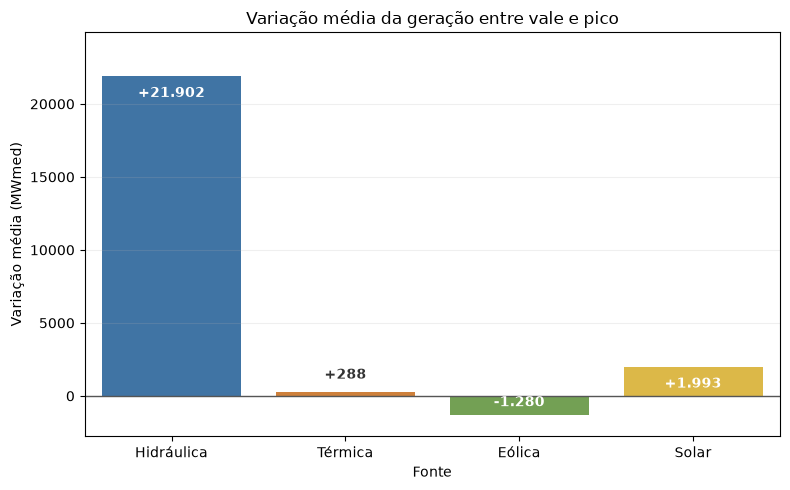

In [44]:
# Prepara os dados para o gráfico, mantendo apenas as fontes de geração
variacao_fontes = (
    variacao_media
    .drop(index="Carga")
    .reset_index()
    .rename(columns={"index": "fonte"})
)

# Cria o gráfico
fig, ax = plt.subplots(figsize=(8, 5))

grafico = sns.barplot(
    data=variacao_fontes,
    x="fonte",
    y="variacao_media_mwmed",
    hue="fonte",
    palette=CORES_FONTES,
    legend=False,
    ax=ax
)

# Linha de referência em zero
ax.axhline(
    0,
    color="#555555",
    linewidth=1
)

# Adiciona espaço acima e abaixo das barras
ax.set_ylim(
    variacao_fontes["variacao_media_mwmed"].min() - 1500,
    variacao_fontes["variacao_media_mwmed"].max() + 3000
)

# Adiciona rótulos de dados
for barra in ax.patches:

    valor = barra.get_height()

    # Formata o valor com separador de milhar
    rotulo = f"{valor:+,.0f}".replace(",", ".")

    # Barras com magnitude suficiente:
    # coloca o rótulo dentro da barra
    if abs(valor) >= 1000:

        if valor > 0:
            y = valor - 700
            va = "top"
        else:
            y = valor + 350
            va = "bottom"

        ax.text(
            barra.get_x() + barra.get_width() / 2,
            y,
            rotulo,
            ha="center",
            va=va,
            fontsize=10,
            fontweight="bold",
            color="white"
        )

    # Barras pequenas:
    # coloca o rótulo fora da barra
    else:

        ax.annotate(
            rotulo,
            xy=(
                barra.get_x() + barra.get_width() / 2,
                valor
            ),
            xytext=(0, 7),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=10,
            fontweight="bold",
            color="#333333"
        )


# Títulos e eixos
ax.set_title(
    "Variação média da geração entre vale e pico"
)

ax.set_xlabel("Fonte")
ax.set_ylabel("Variação média (MWmed)")

# Grade horizontal discreta
ax.grid(
    axis="y",
    alpha=0.20
)

plt.tight_layout()

# Salva na pasta de saídas
plt.savefig(
    PASTA_SAIDAS / "03_variacao_geracao_pico_vale.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

## 8. Composição média horária da geração

Além da comparação entre os horários de pico e vale, será analisado como a composição média da geração varia ao longo das 24 horas do dia.

Para cada hora $h$, será calculada a geração média de cada fonte ao longo de 2025:

$$
\overline{G}_{f,h}
=
\frac{1}{n_h}
\sum_d G_{f,d,h}
$$

onde $f$ representa cada fonte de geração.

Essa análise permite observar como as diferentes fontes participam do atendimento à carga ao longo do dia e contextualiza as diferenças identificadas entre os horários de pico e vale.

In [20]:
# Calcula a geração média de cada fonte para cada hora do dia
geracao_media_horaria = (
    df_sin
    .groupby("hora", as_index=False)
    .agg(
        Hidráulica=("val_gerhidraulica", "mean"),
        Térmica=("val_gertermica", "mean"),
        Eólica=("val_gereolica", "mean"),
        Solar=("val_gersolar", "mean"),
        Carga=("val_carga", "mean")
    )
)

geracao_media_horaria

,hora,Hidráulica,Térmica,Eólica,Solar,Carga
0,0,48386.457707,10374.999178,17232.998499,3.544789,75668.304438
1,1,45272.489268,10277.891612,17132.174304,3.505636,72375.722822
2,2,43262.863748,10253.350655,16945.377255,4.136063,70167.184356
3,3,42180.728474,10246.365518,16750.465701,3.968362,68895.824521
4,4,42160.531833,10241.574032,16514.551879,22.081838,68657.655315
5,5,42984.997471,10225.979434,16121.629592,585.845216,69641.623973
6,6,42095.782732,10151.651877,14471.256167,5470.188710,71905.869425
7,7,38919.106019,10007.335092,12573.554378,13939.350575,75155.798384
8,8,36755.859882,9917.779504,11102.460723,20744.807323,78221.488082
9,9,34814.464808,9853.661259,9382.439137,25900.856907,79627.282904


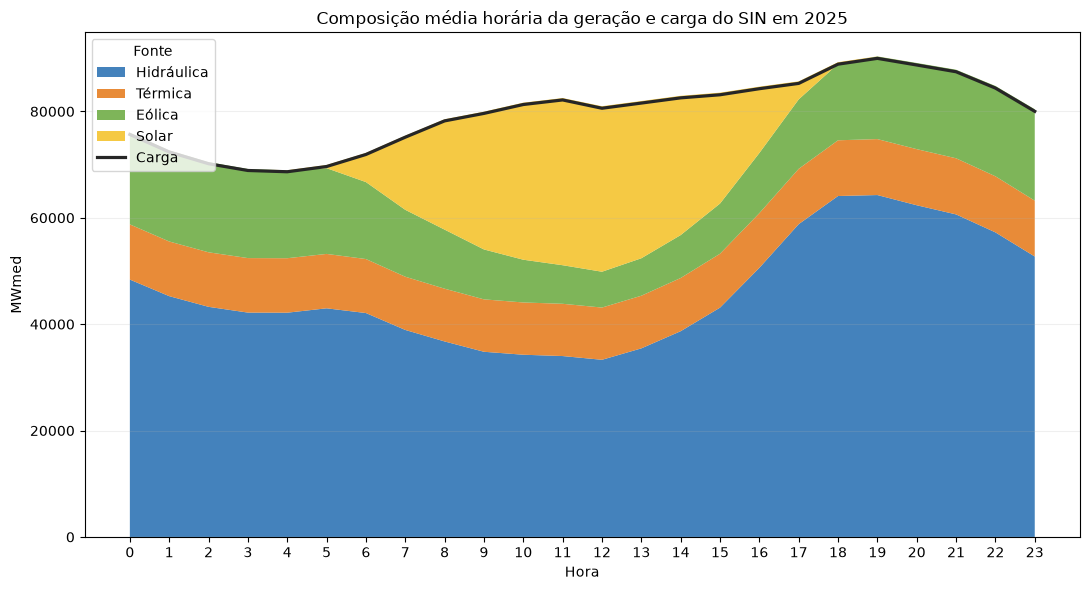

In [21]:
# Define as fontes que serão apresentadas no gráfico
fontes_grafico = [
    "Hidráulica",
    "Térmica",
    "Eólica",
    "Solar"
]

cores_empilhadas = [
    CORES_FONTES["Hidráulica"],
    CORES_FONTES["Térmica"],
    CORES_FONTES["Eólica"],
    CORES_FONTES["Solar"]
]

# Cria o gráfico de área empilhada
fig, ax = plt.subplots(figsize=(11, 6))

ax.stackplot(
    geracao_media_horaria["hora"],
    *[
        geracao_media_horaria[fonte]
        for fonte in fontes_grafico
    ],
    labels=fontes_grafico,
    colors=cores_empilhadas,
    alpha=0.90
)

# Curva de carga
ax.plot(
    geracao_media_horaria["hora"],
    geracao_media_horaria["Carga"],
    color=COR_CARGA,
    linewidth=2.3,
    label="Carga"
)

ax.set_title(
    "Composição média horária da geração e carga do SIN em 2025"
)
ax.set_xlabel("Hora")
ax.set_ylabel("MWmed")
ax.set_xticks(range(24))

ax.legend(
    title="Fonte",
    loc="upper left"
)

ax.grid(
    axis="y",
    alpha=0.20
)

plt.tight_layout()

plt.savefig(
    PASTA_SAIDAS / "04_composicao_horaria_geracao.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

In [22]:
# Calcula a geração total média em cada hora
geracao_media_horaria["Geração total"] = (
    geracao_media_horaria["Hidráulica"]
    + geracao_media_horaria["Térmica"]
    + geracao_media_horaria["Eólica"]
    + geracao_media_horaria["Solar"]
)

# Calcula a participação percentual de cada fonte por hora
for fonte in fontes_grafico:
    geracao_media_horaria[f"{fonte} (%)"] = (
        geracao_media_horaria[fonte]
        / geracao_media_horaria["Geração total"]
        * 100
    )

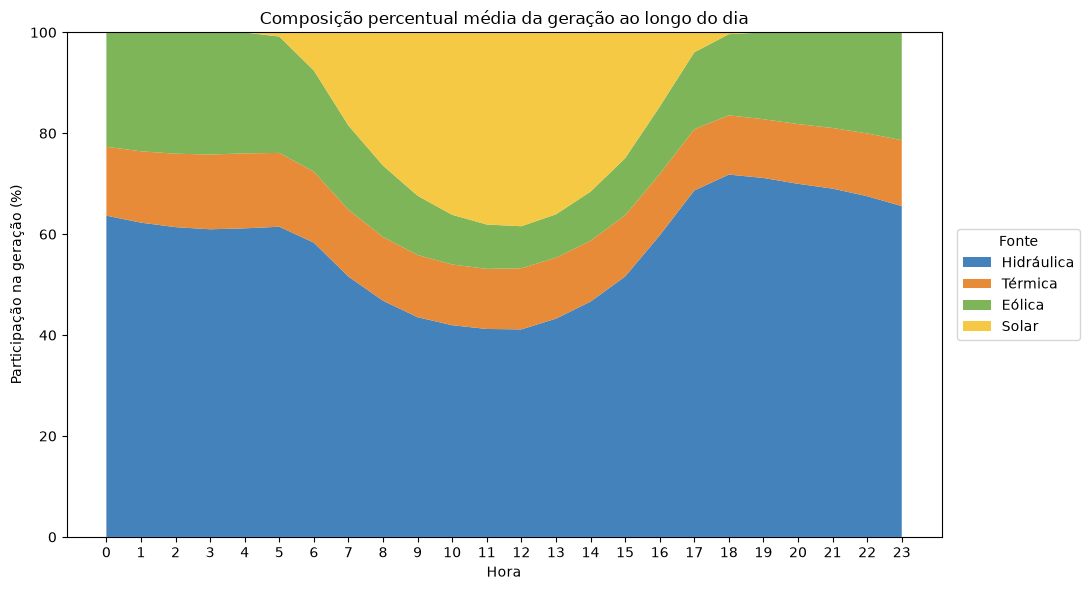

In [23]:
# Cria o gráfico da composição percentual média por hora
fig, ax = plt.subplots(figsize=(11, 6))

ax.stackplot(
    geracao_media_horaria["hora"],
    *[
        geracao_media_horaria[f"{fonte} (%)"]
        for fonte in fontes_grafico
    ],
    labels=fontes_grafico,
    colors=cores_empilhadas,
    alpha=0.90
)

ax.set_title(
    "Composição percentual média da geração ao longo do dia"
)
ax.set_xlabel("Hora")
ax.set_ylabel("Participação na geração (%)")
ax.set_xticks(range(24))
ax.set_ylim(0, 100)

ax.legend(
    title="Fonte",
    loc="center left",
    bbox_to_anchor=(1.01, 0.5)
)

plt.tight_layout()

plt.savefig(
    PASTA_SAIDAS / "05_composicao_percentual_horaria.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

## 9. Evolução mensal da composição da geração

A composição média anual pode ocultar diferenças sazonais ao longo de 2025.

Por esse motivo, será avaliada a participação média das quatro fontes de geração nos horários de pico e vale para cada mês do ano.

In [24]:
# Calcula a participação média mensal das diferentes fontes separadamente para pico e vale
composicao_mensal = (
    df_pico_vale
    .groupby(["mes", "condicao"], as_index=False)
    .agg(
        Hidráulica=("part_hidraulica", "mean"),
        Térmica=("part_termica", "mean"),
        Eólica=("part_eolica", "mean"),
        Solar=("part_solar", "mean")
    )
)

composicao_mensal

,mes,condicao,Hidráulica,Térmica,Eólica,Solar
0,1,Pico,72.045696,7.233487,9.422204,11.298613
1,1,Vale,76.263258,9.050675,11.668683,3.017384
2,2,Pico,68.034426,6.711906,9.696506,15.557161
3,2,Vale,72.909797,8.433092,16.800910,1.856201
4,3,Pico,68.382810,6.694503,10.768680,14.154007
5,3,Vale,70.817740,8.362993,17.804317,3.014951
6,4,Pico,76.900175,8.188043,11.828626,3.083157
7,4,Vale,69.257658,10.606089,18.191882,1.944372
8,5,Pico,73.828281,9.443481,16.675717,0.052520
9,5,Vale,59.887936,12.591737,25.734382,1.785945


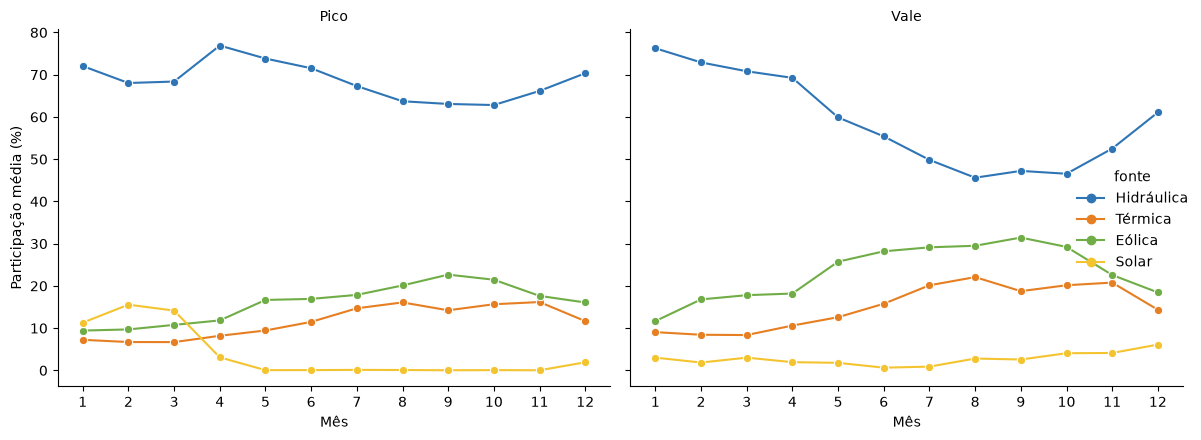

In [25]:
# Converte a tabela para formato longo
composicao_mensal_long = composicao_mensal.melt(
    id_vars=["mes", "condicao"],
    value_vars=["Hidráulica", "Térmica", "Eólica", "Solar"],
    var_name="fonte",
    value_name="participacao"
)

# Cria um painel para pico e outro para vale
grafico = sns.relplot(
    data=composicao_mensal_long,
    x="mes",
    y="participacao",
    hue="fonte",
    col="condicao",
    kind="line",
    marker="o",
    palette=CORES_FONTES,
    height=4.5,
    aspect=1.2
)

grafico.set_axis_labels(
    "Mês",
    "Participação média (%)"
)

grafico.set_titles("{col_name}")

for ax in grafico.axes.flat:
    ax.set_xticks(range(1, 13))

plt.tight_layout()

plt.savefig(
    PASTA_SAIDAS / "06_composicao_mensal_pico_vale.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

## 10. Identificação de dias com comportamento distinto

Para identificar dias que apresentaram comportamento mais distante do padrão, será analisada inicialmente a amplitude diária de carga entre o pico e o vale:

$$
\Delta C_d
=
C_{\text{pico},d}
-
C_{\text{vale},d}
$$

Quanto maior $\Delta C_d$, maior foi a variação da carga entre os extremos daquele dia.

Essa análise possui caráter exploratório.

In [26]:
# Identifica os dias com as maiores diferenças entre a carga do pico e do vale
maiores_variacoes_carga = (
    variacoes["Carga"]
    .sort_values(ascending=False)
    .head(10)
    .to_frame(name="diferenca_pico_vale_mwmed")
)

maiores_variacoes_carga

,diferenca_pico_vale_mwmed
data,
2025-09-08,30786.35
2025-08-11,30452.57
2025-06-23,30382.15
2025-07-14,30050.99
2025-07-21,29766.55
2025-07-07,29698.48
2025-06-16,29371.75
2025-06-30,29282.36
2025-08-18,29073.10


In [28]:
# Identifica os dias com as menores diferenças entre pico e vale
menores_variacoes_carga = (
    variacoes["Carga"]
    .sort_values()
    .head(10)
    .to_frame(name="diferenca_pico_vale_mwmed")
)

menores_variacoes_carga

,diferenca_pico_vale_mwmed
data,
2025-04-05,14625.30
2025-03-15,15289.98
2025-01-25,15306.04
2025-02-01,15860.82
2025-02-15,16025.54
2025-01-11,16167.87
2025-02-22,16201.20
2025-10-18,16214.86
2025-12-13,16267.89


In [29]:
# Recupera a classificação de final de semana para cada data
classificacao_dias = (
    df_sin
    .groupby("data")["fim_semana"]
    .first()
)

variacoes["fim_semana"] = classificacao_dias

In [30]:
# Compara a amplitude média da carga entre dias úteis e finais de semana
amplitude_por_tipo_dia = (
    variacoes
    .groupby("fim_semana")["Carga"]
    .agg(["mean", "median", "min", "max"])
    .rename(index={
        False: "Dia útil",
        True: "Fim de semana"
    })
)

amplitude_por_tipo_dia

,mean,median,min,max
fim_semana,,,,
Dia útil,23840.994713,23945.65,16412.85,30786.35
Fim de semana,20159.055000,20376.69,14625.30,25884.15


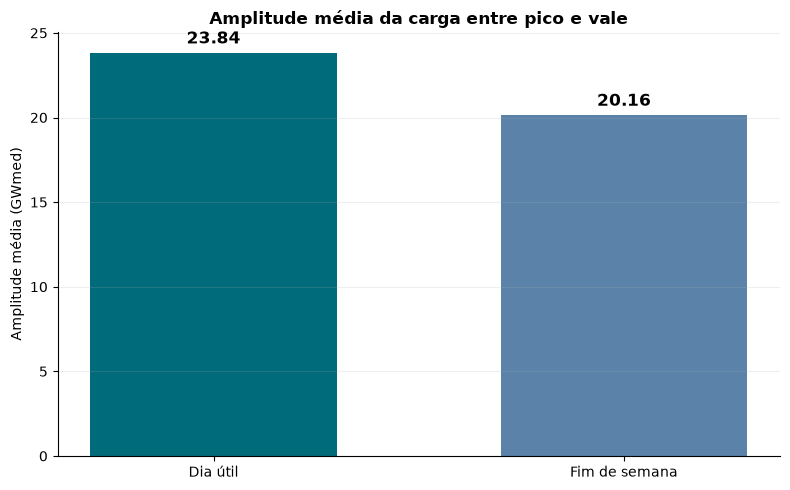

In [31]:
# Cria o gráfico comparando a amplitude média da carga entre dias úteis e finais de semana

fig, ax = plt.subplots(figsize=(8, 5))

# Seleciona a média da amplitude pico-vale
dados_grafico = amplitude_por_tipo_dia["mean"]

# Define as cores
cores_tipo_dia = [
    "#006B7A",  # Dia útil
    "#5B82A9"   # Fim de semana
]

# Cria as barras
barras = ax.bar(
    dados_grafico.index,
    dados_grafico.values / 1000,  # converte MWmed para GWmed
    color=cores_tipo_dia,
    width=0.60
)

# Adiciona os valores acima das barras
for barra, valor in zip(barras, dados_grafico.values / 1000):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        valor + 0.3,
        f"{valor:.2f}",
        ha="center",
        va="bottom",
        fontweight="bold",
        fontsize=12
    )

# Configurações do gráfico
ax.set_title(
    "Amplitude média da carga entre pico e vale",
    fontweight="bold"
)

ax.set_xlabel("")
ax.set_ylabel("Amplitude média (GWmed)")

ax.grid(
    axis="y",
    alpha=0.20
)

# Remove bordas superiores e laterais
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

# Salva o gráfico diretamente na pasta "saidas"
plt.savefig(
    PASTA_SAIDAS / "07_amplitude_dias_uteis_fim_semana.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

## 11. Síntese da análise principal

A análise dos dados horários do SIN em 2025 evidencia diferenças relevantes entre os períodos de pico e vale de carga.

Os principais resultados encontrados foram:

- O dia de maior pico foi: **26/02/2025**.

- O dia de maior vale foi: **10/08/2025**.

- Os **picos diários de carga** concentraram-se principalmente às **18h e 19h**, enquanto os **vales ocorreram predominantemente entre 3h e 4h**.

- A carga média passou de aproximadamente **68,1 GWmed nos vales** para **90,9 GWmed nos picos**, representando uma diferença média diária de aproximadamente:

$$
\Delta C \approx 22{,}8\ \text{GWmed}
$$

- A **geração hidráulica apresentou a maior variação média entre vale e pico**, aumentando aproximadamente:

$$
\Delta G_{hidráulica} \approx 21{,}9\ \text{GWmed}
$$

- A geração térmica apresentou aumento médio de aproximadamente **0,3 GWmed**, enquanto a geração solar apresentou aumento médio próximo de **2,0 GWmed**. A geração eólica apresentou, em média, redução de aproximadamente **1,3 GWmed** entre vale e pico.

- A participação hidráulica média aumentou de aproximadamente **58,9% no vale para 68,7% no pico**, evidenciando o papel dessa fonte no atendimento aos períodos de maior carga.

- A composição da geração não permaneceu constante ao longo do ano. A análise mensal mostrou variação relevante das participações hidráulica, térmica e eólica, indicando influência da sazonalidade sobre o atendimento aos períodos de pico e vale.

- A diferença entre pico e vale também variou entre os dias. Nos **dias úteis**, a amplitude média foi de aproximadamente **23,8 GWmed**, enquanto nos **finais de semana** foi de aproximadamente **20,2 GWmed**.

Assim, os resultados indicam que o atendimento ao aumento da carga entre os períodos de vale e pico em 2025 esteve associado principalmente ao aumento da geração hidráulica, enquanto as demais fontes apresentaram contribuições e comportamentos distintos ao longo do dia e do ano.

# PARTE II - Análises Complementares

## 12. Análise complementar da carga líquida

Como complemento à análise principal, será avaliado o comportamento da carga líquida, definida neste projeto como:

$$
C_{líquida}
=
C_{bruta}
-
G_{eólica}
-
G_{solar}
$$

O objetivo é verificar como a contribuição das fontes eólica e solar modifica o perfil horário da demanda a ser atendida pelas demais fontes e se o horário de maior carga líquida coincide com o horário de maior carga bruta.

In [32]:
# Calcula o perfil horário médio da carga bruta e da carga líquida
perfil_cargas = (
    df_sin
    .groupby("hora", as_index=False)
    .agg(
        carga_bruta=("val_carga", "mean"),
        carga_liquida=("carga_liquida", "mean")
    )
)

perfil_cargas

,hora,carga_bruta,carga_liquida
0,0,75668.304438,58431.761151
1,1,72375.722822,55240.042882
2,2,70167.184356,53217.671038
3,3,68895.824521,52141.390458
4,4,68657.655315,52121.021597
5,5,69641.623973,52934.149164
6,6,71905.869425,51964.424548
7,7,75155.798384,48642.893430
8,8,78221.488082,46374.220036
9,9,79627.282904,44343.986860


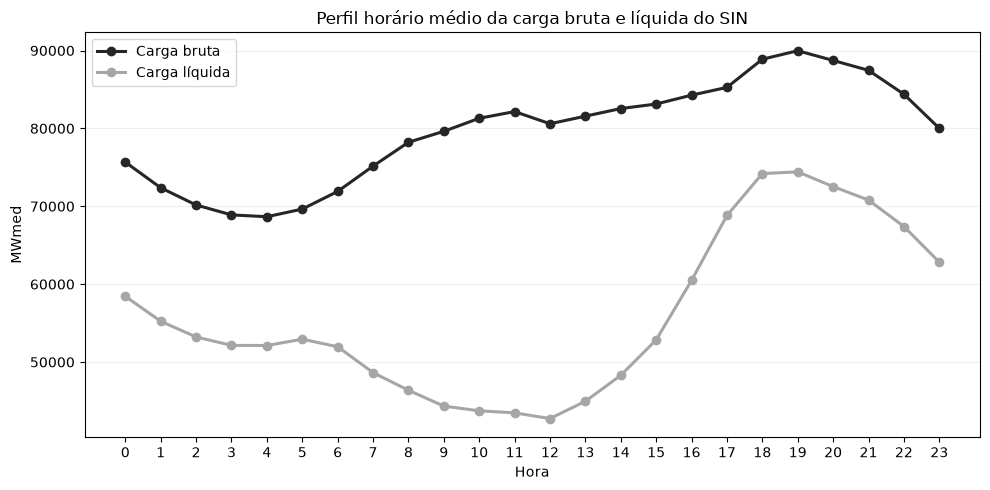

In [33]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    perfil_cargas["hora"],
    perfil_cargas["carga_bruta"],
    marker="o",
    color=COR_CARGA,
    linewidth=2.2,
    label="Carga bruta"
)

ax.plot(
    perfil_cargas["hora"],
    perfil_cargas["carga_liquida"],
    marker="o",
    color=COR_CARGA_LIQUIDA,
    linewidth=2.2,
    label="Carga líquida"
)

ax.set_title(
    "Perfil horário médio da carga bruta e líquida do SIN"
)
ax.set_xlabel("Hora")
ax.set_ylabel("MWmed")
ax.set_xticks(range(24))

ax.legend()

ax.grid(
    axis="y",
    alpha=0.20
)

plt.tight_layout()

plt.savefig(
    PASTA_SAIDAS / "08_carga_bruta_liquida.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

In [34]:
# Identifica os horários dos picos diários da carga bruta e da carga líquida
picos_comparacao = (
    df_sin
    .groupby("data")
    .agg(
        indice_pico_bruta=("val_carga", "idxmax"),
        indice_pico_liquida=("carga_liquida", "idxmax")
    )
)

picos_comparacao["hora_pico_bruta"] = (
    df_sin.loc[
        picos_comparacao["indice_pico_bruta"],
        "hora"
    ].values
)

picos_comparacao["hora_pico_liquida"] = (
    df_sin.loc[
        picos_comparacao["indice_pico_liquida"],
        "hora"
    ].values
)

picos_comparacao.head()

,indice_pico_bruta,indice_pico_liquida,hora_pico_bruta,hora_pico_liquida
data,,,,
2025-01-01,20,20,20,20
2025-01-02,44,44,20,20
2025-01-03,68,68,20,20
2025-01-04,92,92,20,20
2025-01-05,116,116,20,20


In [40]:
# Identifica os horários dos vales diários da carga bruta e da carga líquida
vales_comparacao = (
    df_sin
    .groupby("data")
    .agg(
        indice_vale_bruta=("val_carga", "idxmin"),
        indice_vale_liquida=("carga_liquida", "idxmin")
    )
)

# Recupera a hora do vale da carga bruta
vales_comparacao["hora_vale_bruta"] = (
    df_sin.loc[
        vales_comparacao["indice_vale_bruta"],
        "hora"
    ].values
)

# Recupera a hora do vale da carga líquida
vales_comparacao["hora_vale_liquida"] = (
    df_sin.loc[
        vales_comparacao["indice_vale_liquida"],
        "hora"
    ].values
)

vales_comparacao.head()

,indice_vale_bruta,indice_vale_liquida,hora_vale_bruta,hora_vale_liquida
data,,,,
2025-01-01,8,9,8,9
2025-01-02,29,32,5,8
2025-01-03,53,57,5,9
2025-01-04,78,84,6,12
2025-01-05,103,109,7,13


In [35]:
# Verifica quantos dias apresentaram o mesmo horário de pico para carga bruta e carga líquida
picos_comparacao["mesmo_horario"] = (
    picos_comparacao["hora_pico_bruta"]
    == picos_comparacao["hora_pico_liquida"]
)

quantidade_coincidentes = (
    picos_comparacao["mesmo_horario"].sum()
)

percentual_coincidentes = (
    picos_comparacao["mesmo_horario"].mean() * 100
)

print(
    f"Picos no mesmo horário: "
    f"{quantidade_coincidentes} de {len(picos_comparacao)} dias"
)

print(
    f"Percentual de coincidência: "
    f"{percentual_coincidentes:.1f}%"
)

Picos no mesmo horário: 228 de 365 dias
Percentual de coincidência: 62.5%


In [41]:
# Verifica quantos dias apresentaram o mesmo horário de vale para a carga bruta e para a carga líquida
vales_comparacao["mesmo_horario"] = (
    vales_comparacao["hora_vale_bruta"]
    == vales_comparacao["hora_vale_liquida"]
)

# Quantidade de dias com coincidência
quantidade_coincidentes_vale = (
    vales_comparacao["mesmo_horario"].sum()
)

# Percentual de dias com coincidência
percentual_coincidentes_vale = (
    vales_comparacao["mesmo_horario"].mean() * 100
)

print(
    f"Vales no mesmo horário: "
    f"{quantidade_coincidentes_vale} de {len(vales_comparacao)} dias"
)

print(
    f"Percentual de coincidência: "
    f"{percentual_coincidentes_vale:.1f}%"
)

Vales no mesmo horário: 5 de 365 dias
Percentual de coincidência: 1.4%


In [42]:
# Consolida os resultados de coincidência entre carga bruta e carga líquida
coincidencia_pico_vale = pd.DataFrame({
    "Condição": ["Pico", "Vale"],
    "Dias coincidentes": [
        quantidade_coincidentes,
        quantidade_coincidentes_vale
    ],
    "Total de dias": [
        len(picos_comparacao),
        len(vales_comparacao)
    ],
    "Coincidência (%)": [
        percentual_coincidentes,
        percentual_coincidentes_vale
    ]
})

coincidencia_pico_vale

,Condição,Dias coincidentes,Total de dias,Coincidência (%)
0,Pico,228,365,62.465753
1,Vale,5,365,1.369863


## 13. Análise complementar por subsistema

A análise principal considera o SIN de forma agregada. Como complemento, será realizada uma comparação simplificada da composição média da geração entre os quatro subsistemas.

O objetivo é verificar se o perfil agregado do SIN representa comportamentos semelhantes entre as regiões ou se existem diferenças relevantes na participação das fontes.

In [36]:
# Seleciona apenas os quatro subsistemas
df_subsistemas = df[
    df["id_subsistema"].isin(["N", "NE", "S", "SE"])
].copy()

# Calcula a participação média das fontes por subsistema
composicao_subsistemas = (
    df_subsistemas
    .groupby("nom_subsistema")
    .agg(
        Hidráulica=("part_hidraulica", "mean"),
        Térmica=("part_termica", "mean"),
        Eólica=("part_eolica", "mean"),
        Solar=("part_solar", "mean")
    )
)

composicao_subsistemas

,Hidráulica,Térmica,Eólica,Solar
nom_subsistema,,,,
NORDESTE,17.526581,3.886635,60.687742,17.899042
NORTE,65.079265,25.387279,2.598614,6.934842
SUDESTE/CENTRO-OESTE,69.895997,17.061869,0.202183,12.839951
SUL,70.691301,10.814586,6.998295,11.495818


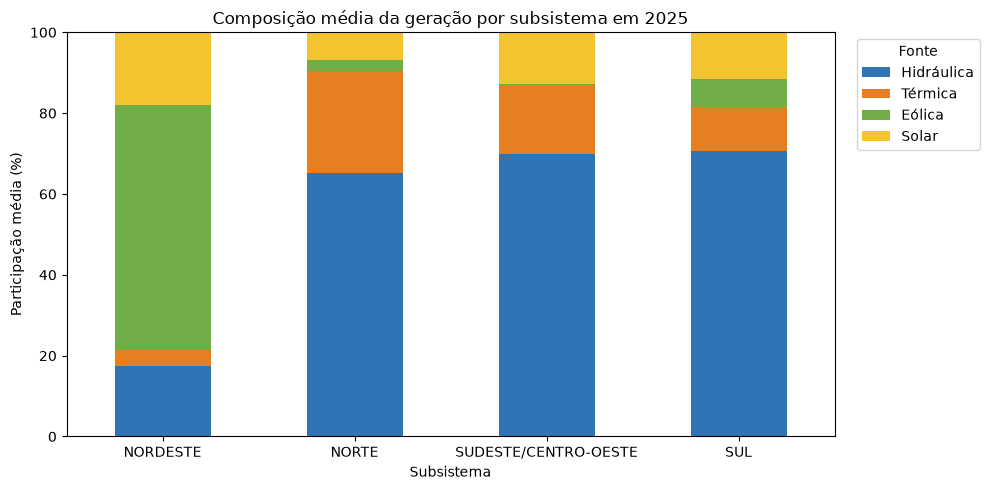

In [37]:
fig, ax = plt.subplots(figsize=(10, 5))

composicao_subsistemas.plot(
    kind="bar",
    stacked=True,
    color=cores_empilhadas,
    ax=ax
)

ax.set_title(
    "Composição média da geração por subsistema em 2025"
)
ax.set_xlabel("Subsistema")
ax.set_ylabel("Participação média (%)")
ax.set_ylim(0, 100)

ax.legend(
    title="Fonte",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    PASTA_SAIDAS / "09_composicao_subsistemas.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

In [38]:
# Resume carga, geração e intercâmbio médios para cada subsistema
balanco_subsistemas = (
    df_subsistemas
    .groupby("nom_subsistema")
    .agg(
        carga_media=("val_carga", "mean"),
        geracao_media=("geracao_total", "mean"),
        intercambio_medio=("val_intercambio", "mean")
    )
)

balanco_subsistemas

,carga_media,geracao_media,intercambio_medio
nom_subsistema,,,
NORDESTE,13266.864794,19530.365426,6263.500632
NORTE,8311.701382,10481.090517,2169.389135
SUDESTE/CENTRO-OESTE,44225.909113,38586.032746,-5639.876367
SUL,13804.431484,11358.443315,-2445.988169


## 14. Síntese das análises complementares

As análises complementares acrescentaram duas evidências à análise principal:

- A retirada das gerações **eólica e solar** modifica significativamente o perfil horário da carga. O pico da carga bruta e da carga líquida ocorreu no mesmo horário em **62,5% dos dias**, enquanto para o vale essa coincidência ocorreu em apenas **1,4% dos dias**. Portanto, o efeito dessas fontes sobre o horário do mínimo diário foi muito mais pronunciado do que sobre o horário do máximo.

- A análise por subsistema evidenciou **diferenças na composição da geração entre as regiões**, mostrando que o comportamento agregado do SIN resulta da combinação de perfis regionais distintos e dos intercâmbios de energia entre os subsistemas.